# Phase 5: Job Description Text Exploration

**Author:** Beth Spornitz  
**Course:** 44-620 Web Mining and Applied NLP  
**Date:** November 2026

## Research Question

How do word frequencies, co-occurrence patterns, and two-word skill phrases differ across Data Analyst, Business Analyst, and Data Governance job descriptions?

For this project, I adapted the instructor's Module 3 example to analyze job descriptions instead of the original animal and vehicle categories.

The analysis uses 12 paraphrased job descriptions, with four descriptions in each of three categories:

- Data Analyst
- Business Analyst
- Data Governance

The notebook explores token frequencies, category vocabulary, co-occurrence patterns, and bigrams before applying any machine learning models.

In [9]:
from collections import defaultdict
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

# Find the project folder by locating the CSV file.
cwd = Path.cwd().resolve()

ROOT_PATH = next(
    (
        folder
        for folder in (cwd, *cwd.parents)
        if (folder / "data" / "job_descriptions.csv").is_file()
    ),
    None,
)

if ROOT_PATH is None:
    raise FileNotFoundError(
        "Could not find data/job_descriptions.csv in this folder or its parent folders."
    )

DATA_PATH = ROOT_PATH / "data" / "job_descriptions.csv"

# Verify that the CSV file exists.
print(f"Loading data from: {DATA_PATH}")
print(f"File exists: {DATA_PATH.is_file()}")

# Load the same corpus used in the custom Python script.
corpus: list[dict[str, str]] = []

with DATA_PATH.open(encoding="utf-8-sig", newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        corpus.append(
            {
                "category": row["role"],
                "text": row["description"],
            }
        )

print(f"Corpus contains {len(corpus)} documents.")

# Count the number of documents in each job category.
category_counts: dict[str, int] = {}

for doc in corpus:
    category = doc["category"]
    category_counts[category] = category_counts.get(category, 0) + 1

for category, count in sorted(category_counts.items()):
    print(f"{category}: {count}")

# Verify that the expected dataset loaded correctly.
assert len(corpus) == 12
assert category_counts == {
    "Business Analyst": 4,
    "Data Analyst": 4,
    "Data Governance": 4,
}

print("Dataset verification passed.")

Loading data from: C:\Repos\nlp-03-text-exploration-custom\data\job_descriptions.csv
File exists: True
Corpus contains 12 documents.
Business Analyst: 4
Data Analyst: 4
Data Governance: 4
Dataset verification passed.


## 1. Tokenization and Cleaning

The text is converted to lowercase, split into individual tokens, and stripped of common punctuation.

The instructor's original tokenizer excludes tokens of two characters or fewer. However, that rule also removes the meaningful technical abbreviation **BI** from **Power BI**.

I changed the tokenizer to keep `bi` while leaving the instructor's other preprocessing rules the same.

Common words such as `and` and `with` are not removed, so they may appear among the most frequent tokens.

In [10]:
# Define a function to tokenize text by lowercasing, splitting on whitespace,
# and stripping common punctuation.
# Retain "bi" because it is part of the technical skill "Power BI".
def tokenize(text: str) -> list[str]:
    """Tokenize the input text into a list of cleaned tokens."""
    tokens = text.lower().split()
    return [
        t.strip(".,:;!?()[]\"'")
        for t in tokens
        if len(t) > 2 or t.lower().strip(".,:;!?()[]\"'") == "bi"
    ]


# Create token records containing category and token.
records_list: list[dict[str, str]] = []

for doc in corpus:
    tokens = tokenize(doc["text"])
    for token in tokens:
        records_list.append({"category": doc["category"], "token": token})

token_df: pl.DataFrame = pl.DataFrame(records_list)

print("Tokenization complete.")
print(f"Total token occurrences: {token_df.height}")
token_df.head(10)

Tokenization complete.
Total token occurrences: 321


category,token
str,str
"""Data Governance""","""review"""
"""Data Governance""","""data"""
"""Data Governance""","""use"""
"""Data Governance""","""requests"""
"""Data Governance""","""and"""
"""Data Governance""","""governance"""
"""Data Governance""","""requirements"""
"""Data Governance""","""coordinate"""
"""Data Governance""","""approvals"""


## 2. Global Token Frequencies

Global token frequencies show how often individual words appear across all 12 job descriptions.

This helps identify commonly repeated terms, but frequent words are not necessarily the most useful. For example, and appeared more often than technical skills or job-specific terms.

In [11]:
# Frequency distribution = how often each token appears.
global_freq_df: pl.DataFrame = (
    token_df.group_by("token").len().sort("len", descending=True)
)

print("Top 10 global tokens:")
global_freq_df.head(10)

Top 10 global tokens:


token,len
str,u64
"""and""",47
"""data""",21
"""business""",11
"""develop""",8
"""with""",8
"""governance""",7
"""support""",7
"""stakeholders""",6
"""quality""",6


## 3. Token Frequencies by Job Category

The next analysis compares vocabulary across the three job categories.

Each category contains four job descriptions, allowing us to examine the words most frequently used within each group.

The top five lists also include common words like and and with because I did not remove stop words.

In [12]:
# Compare token usage across categories.
category_freq_df: pl.DataFrame = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len"], descending=True)
)

# Identify the top five tokens for each category.
top_per_category_dict: dict[str, list[str]] = {}

for category in sorted(token_df["category"].unique().to_list()):
    subset_df = category_freq_df.filter(pl.col("category") == category).head(5)
    top_tokens_list = subset_df["token"].to_list()
    top_per_category_dict[category] = top_tokens_list

    print(f"{category.upper()} top tokens: {top_tokens_list}")

# Display the top-five frequency records for all categories.
top_category_rows = []

for category in sorted(top_per_category_dict):
    subset_df = category_freq_df.filter(pl.col("category") == category).head(5)
    top_category_rows.extend(subset_df.to_dicts())

pl.DataFrame(top_category_rows)

BUSINESS ANALYST top tokens: ['and', 'business', 'with', 'user', 'requirements']
DATA ANALYST top tokens: ['and', 'data', 'sql', 'develop', 'dashboards']
DATA GOVERNANCE top tokens: ['and', 'data', 'governance', 'quality', 'metadata']


category,token,len
str,str,i64
"""Business Analyst""","""and""",16
"""Business Analyst""","""business""",6
"""Business Analyst""","""with""",5
"""Business Analyst""","""user""",4
"""Business Analyst""","""requirements""",4
…,…,…
"""Data Governance""","""and""",15
"""Data Governance""","""data""",15
"""Data Governance""","""governance""",6


## 4. Co-occurrence and Context Windows

Co-occurrence looks at which words appear near certain words in the text.

A context window of three includes up to three tokens before and three tokens after each target word, excluding the target itself.

The selected terms are:

- `data`
- `business`
- `governance`
- `quality`

This helps show which words are often found near each other. However, just because two words appear close together doesn't necessarily mean they are related.

In [13]:
WINDOW_SIZE: int = 3

# Store the surrounding context tokens for each target word.
co_occurrence_dict: dict[str, list[str]] = defaultdict(list)

for doc in corpus:
    tokens = tokenize(doc["text"])
    for i, token in enumerate(tokens):
        start = max(0, i - WINDOW_SIZE)
        end = min(len(tokens), i + WINDOW_SIZE + 1)
        context = tokens[start:end]

        for ctx in context:
            if ctx != token:
                co_occurrence_dict[token].append(ctx)

# Display the first 10 context tokens for each selected word.
for target in ["data", "business", "governance", "quality"]:
    print(f"\nContext for '{target}':")
    print(co_occurrence_dict[target][:10])


Context for 'data':
['review', 'use', 'requests', 'and', 'metadata', 'management', 'and', 'lineage', 'documentation', 'evaluate']

Context for 'business':
['coordinate', 'approvals', 'with', 'and', 'technology', 'stakeholders', 'communicate', 'analytical', 'findings', 'stakeholders']

Context for 'governance':
['use', 'requests', 'and', 'requirements', 'coordinate', 'approvals', 'quality', 'controls', 'and', 'compliance']

Context for 'quality':
['documentation', 'evaluate', 'data', 'controls', 'and', 'governance', 'patterns', 'validate', 'data', 'and']


## 5. Bigram Analysis

Bigrams are pairs of consecutive tokens. They can reveal repeated phrases that are more informative than individual words.

This analysis is especially useful for identifying phrases such as `data quality`, `data governance`, and `power bi`.

The Power BI example shows why the way we clean text matters. If the code removed all two-character words, it would also remove bi, preventing power bi from being counted as a bigram.

In [14]:
# Create bigrams by pairing each token with the next token.
bigrams_list: list[tuple[str, str]] = []

for doc in corpus:
    tokens = tokenize(doc["text"])
    for i in range(len(tokens) - 1):
        bigrams_list.append((tokens[i], tokens[i + 1]))

bigram_df: pl.DataFrame = pl.DataFrame(
    {"bigram": [f"{a} {b}" for a, b in bigrams_list]}
)

bigram_freq_df: pl.DataFrame = (
    bigram_df.group_by("bigram").len().sort("len", descending=True)
)

print("Top 10 bigrams:")
print(bigram_freq_df.head(10))

print("\nPower BI bigram frequency:")
print(bigram_freq_df.filter(pl.col("bigram") == "power bi"))

# Verify key phrases against the actual calculated frequencies.
for phrase in ["data quality", "data governance", "power bi"]:
    result = bigram_freq_df.filter(pl.col("bigram") == phrase)
    count = result["len"][0] if result.height else 0
    print(f"{phrase}: {count}")

Top 10 bigrams:
shape: (10, 2)
┌───────────────────┬─────┐
│ bigram            ┆ len │
│ ---               ┆ --- │
│ str               ┆ u64 │
╞═══════════════════╪═════╡
│ data quality      ┆ 6   │
│ dashboards and    ┆ 5   │
│ and data          ┆ 4   │
│ and support       ┆ 4   │
│ stakeholders and  ┆ 4   │
│ collaborate with  ┆ 4   │
│ data governance   ┆ 4   │
│ power bi          ┆ 3   │
│ data lineage      ┆ 3   │
│ document business ┆ 3   │
└───────────────────┴─────┘

Power BI bigram frequency:
shape: (1, 2)
┌──────────┬─────┐
│ bigram   ┆ len │
│ ---      ┆ --- │
│ str      ┆ u64 │
╞══════════╪═════╡
│ power bi ┆ 3   │
└──────────┴─────┘
data quality: 6
data governance: 4
power bi: 3


## 6. Visualization: Comparing Job Categories

The following visualization compares the five most frequent tokens in each job category.

Instead of showing only one category, the custom notebook displays all three categories so that differences in vocabulary are easier to examine.

The charts use the calculated category frequencies, not manually entered values.

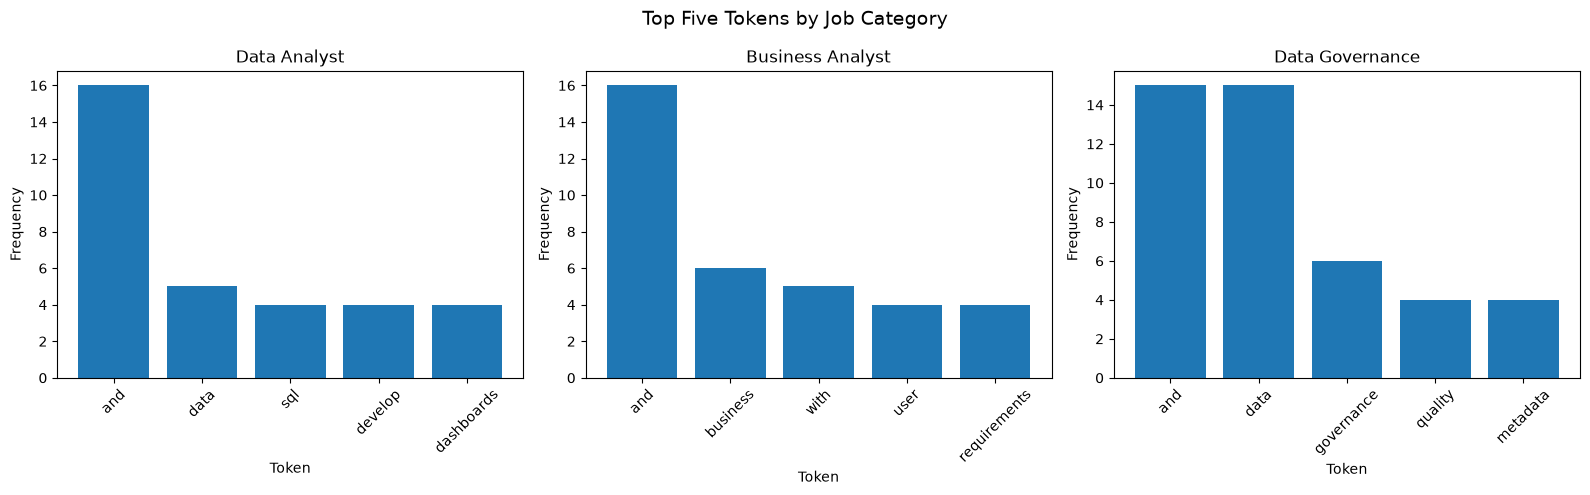

In [15]:
categories = ["Data Analyst", "Business Analyst", "Data Governance"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, category in zip(axes, categories):
    subset_df = category_freq_df.filter(pl.col("category") == category).head(5)

    ax.bar(subset_df["token"].to_list(), subset_df["len"].to_list())
    ax.set_title(category)
    ax.set_xlabel("Token")
    ax.set_ylabel("Frequency")
    ax.tick_params(axis="x", labelrotation=45)

fig.suptitle("Top Five Tokens by Job Category", fontsize=14)
plt.tight_layout()

# Save the chart for the project documentation.
image_folder = ROOT_PATH / "docs" / "images"
image_folder.mkdir(parents=True, exist_ok=True)
fig.savefig(image_folder / "job_category_top_tokens.png", dpi=150, bbox_inches="tight")

plt.show()

## 7. Results and Interpretation

### Global vocabulary

Across the 12 descriptions, `and` was the most frequent token, appearing 47 times. The word `data` appeared 21 times, followed by `business` with 11 occurrences.

The prominence of `and` demonstrates a limitation of the simple tokenizer: common words remain in the analysis and can dominate frequency rankings.

### Differences between job categories

The three job categories show different vocabulary patterns:

- **Data Analyst:** Frequent terms include `develop`, `dashboards`, and `sql`, suggesting an emphasis on technical analysis and reporting.
- **Business Analyst:** Frequent terms include `business`, `user`, and `requirements`, suggesting an emphasis on business needs and requirements gathering.
- **Data Governance:** Frequent terms include `governance`, `quality`, and `metadata`, suggesting an emphasis on managing and documenting data.

These differences are consistent with the focus of the job descriptions included in this sample.

### Bigrams and technical skills

The phrase `data quality` occurred six times, while `data governance` occurred four times.

The phrase `power bi` occurred three times after the tokenizer was modified to preserve the abbreviation `bi`.

This illustrates how a preprocessing decision can affect which technical skills are visible in the results.

### Co-occurrence patterns

The context surrounding `data`, `business`, `governance`, and `quality` included terms related to documentation, metadata, controls, stakeholders, and compliance.

These patterns show which words appear near each other, but they don't necessarily mean the words are related.

### Limitations

This is a small selected sample of 12 paraphrased job descriptions, with four descriptions per category. It should not be treated as representative of the entire job market.

The tokenizer uses simple whitespace splitting and punctuation removal. It does not perform stemming, lemmatization, or general stop-word removal. Some phrases may be split or counted differently because of those choices.

The descriptions were paraphrased, so the results reflect the wording of the paraphrased dataset rather than exact employer postings.

### Next Steps

A future analysis could use a larger set of job descriptions, apply consistent stop-word handling, preserve additional technical abbreviations, and compare skill phrases by job category.

The results could also be used to identify overlapping skills and help guide professional development.

In [16]:
# Confirm that the notebook results match the expected dataset
# and the verified findings from the custom Python script.

assert len(corpus) == 12
assert len(top_per_category_dict) == 3

expected_global = {
    "and": 47,
    "data": 21,
    "business": 11,
}

for token, expected_count in expected_global.items():
    result = global_freq_df.filter(pl.col("token") == token)
    assert result.height == 1
    assert result["len"][0] == expected_count

expected_bigrams = {
    "data quality": 6,
    "data governance": 4,
    "power bi": 3,
}

for phrase, expected_count in expected_bigrams.items():
    result = bigram_freq_df.filter(pl.col("bigram") == phrase)
    assert result.height == 1
    assert result["len"][0] == expected_count

print("Verification passed: dataset, global frequencies, and key bigrams match.")

Verification passed: dataset, global frequencies, and key bigrams match.
